In [1]:

# Import libraries for data handling
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for splitting data and scaling features
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy import stats

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Import model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    classification_report
)

# Set the visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


In [3]:

import pandas as pd

# Load the Parkinson's dataset from the local computer
df = pd.read_csv(r"C:\Users\anoop\Downloads\parkinsons.data")

# Display the number of rows and columns
print("Dataset shape (rows, columns):", df.shape)

# Display the first five rows
print("\nFirst five rows:")
df.head()



Dataset shape (rows, columns): (195, 24)

First five rows:


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [4]:

# Remove the recording identifier because it is not a voice measurement
if 'name' in df.columns:
    df = df.drop('name', axis=1)
    print("Removed the 'name' column because it is an identifier.")

# Display the remaining column names
print("\nRemaining columns:")
print(df.columns.tolist())

# Display the first five rows
df.head()


Removed the 'name' column because it is an identifier.

Remaining columns:
['MDVP:Fo(Hz)', 'MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 'MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP', 'MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA', 'NHR', 'HNR', 'status', 'RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE']


,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [5]:

# Separate the input features from the target column
X = df.drop('status', axis=1)
y = df['status']

# Display the shapes of the features and target
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)


Features (X) shape: (195, 22)
Target (y) shape: (195,)


In [6]:

# Count missing values in each column
print("Missing values count per column:")
print(df.isnull().sum())


Missing values count per column:
MDVP:Fo(Hz)         0
MDVP:Fhi(Hz)        0
MDVP:Flo(Hz)        0
MDVP:Jitter(%)      0
MDVP:Jitter(Abs)    0
MDVP:RAP            0
MDVP:PPQ            0
Jitter:DDP          0
MDVP:Shimmer        0
MDVP:Shimmer(dB)    0
Shimmer:APQ3        0
Shimmer:APQ5        0
MDVP:APQ            0
Shimmer:DDA         0
NHR                 0
HNR                 0
status              0
RPDE                0
DFA                 0
spread1             0
spread2             0
D2                  0
PPE                 0
dtype: int64


In [7]:

# Create the feature scaler
scaler = StandardScaler()

# Split the original features into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit the scaler using only the training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing features using the same scaler
X_test_scaled = scaler.transform(X_test)

# Display the number of training and testing records
print("Training set samples:", X_train_scaled.shape[0])
print("Testing set samples:", X_test_scaled.shape[0])


Training set samples: 156
Testing set samples: 39


In [8]:

# Display the number of training and testing samples
print("Training set samples:", X_train_scaled.shape[0])
print("Testing set samples:", X_test_scaled.shape[0])


Training set samples: 156
Testing set samples: 39


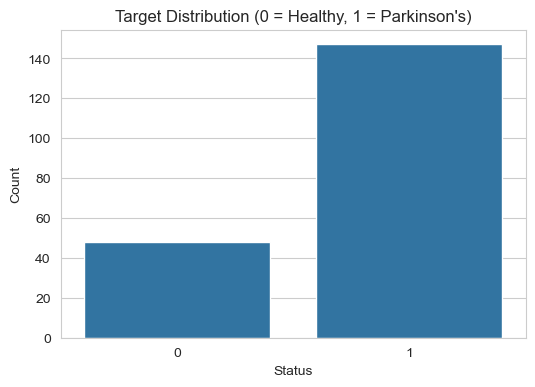

In [9]:

# Plot the distribution of the target variable
plt.figure(figsize=(6, 4))
sns.countplot(x=y)

plt.title("Target Distribution (0 = Healthy, 1 = Parkinson's)")
plt.xlabel("Status")
plt.ylabel("Count")
plt.show()


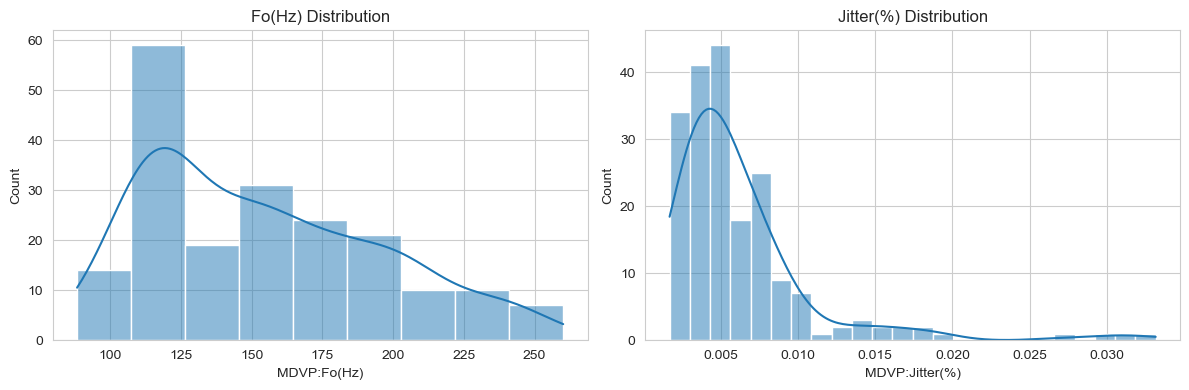

In [10]:

# Create histograms for two voice features
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(X["MDVP:Fo(Hz)"], kde=True, ax=axes[0])
axes[0].set_title("Fo(Hz) Distribution")

sns.histplot(X["MDVP:Jitter(%)"], kde=True, ax=axes[1])
axes[1].set_title("Jitter(%) Distribution")

plt.tight_layout()
plt.show()


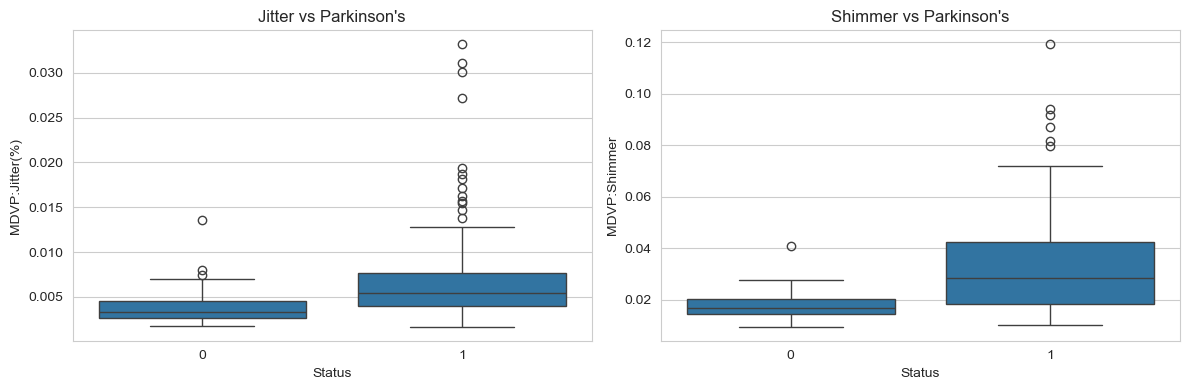

In [11]:

# Create boxplots to compare voice features by target status
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=y, y=X["MDVP:Jitter(%)"], ax=axes[0])
axes[0].set_title("Jitter vs Parkinson's")
axes[0].set_xlabel("Status")
axes[0].set_ylabel("MDVP:Jitter(%)")

sns.boxplot(x=y, y=X["MDVP:Shimmer"], ax=axes[1])
axes[1].set_title("Shimmer vs Parkinson's")
axes[1].set_xlabel("Status")
axes[1].set_ylabel("MDVP:Shimmer")

plt.tight_layout()
plt.show()


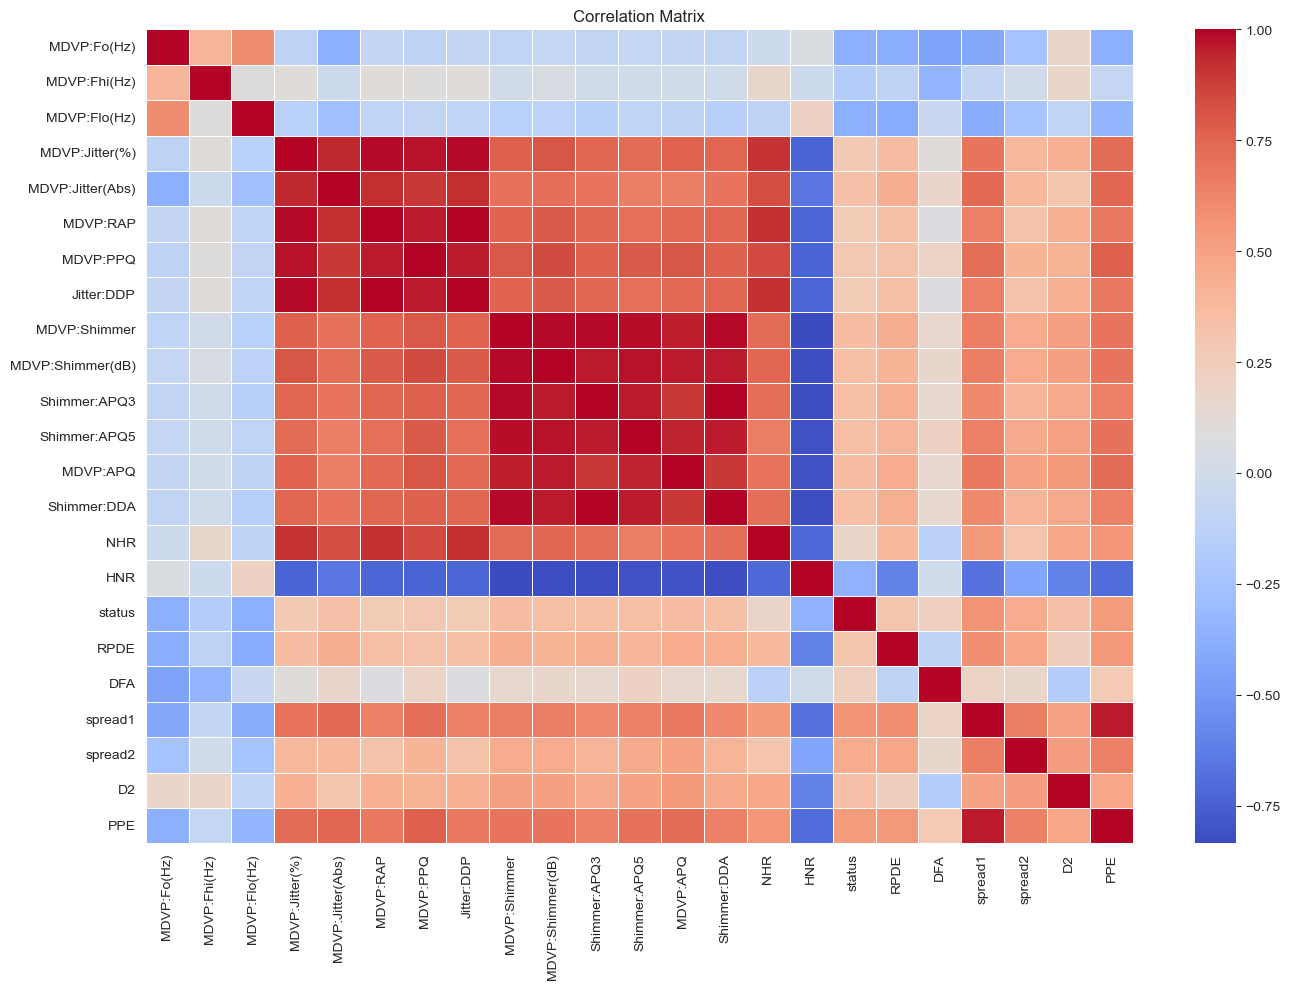

In [12]:

# Create a correlation heatmap for the dataset
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.corr(),
    annot=False,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


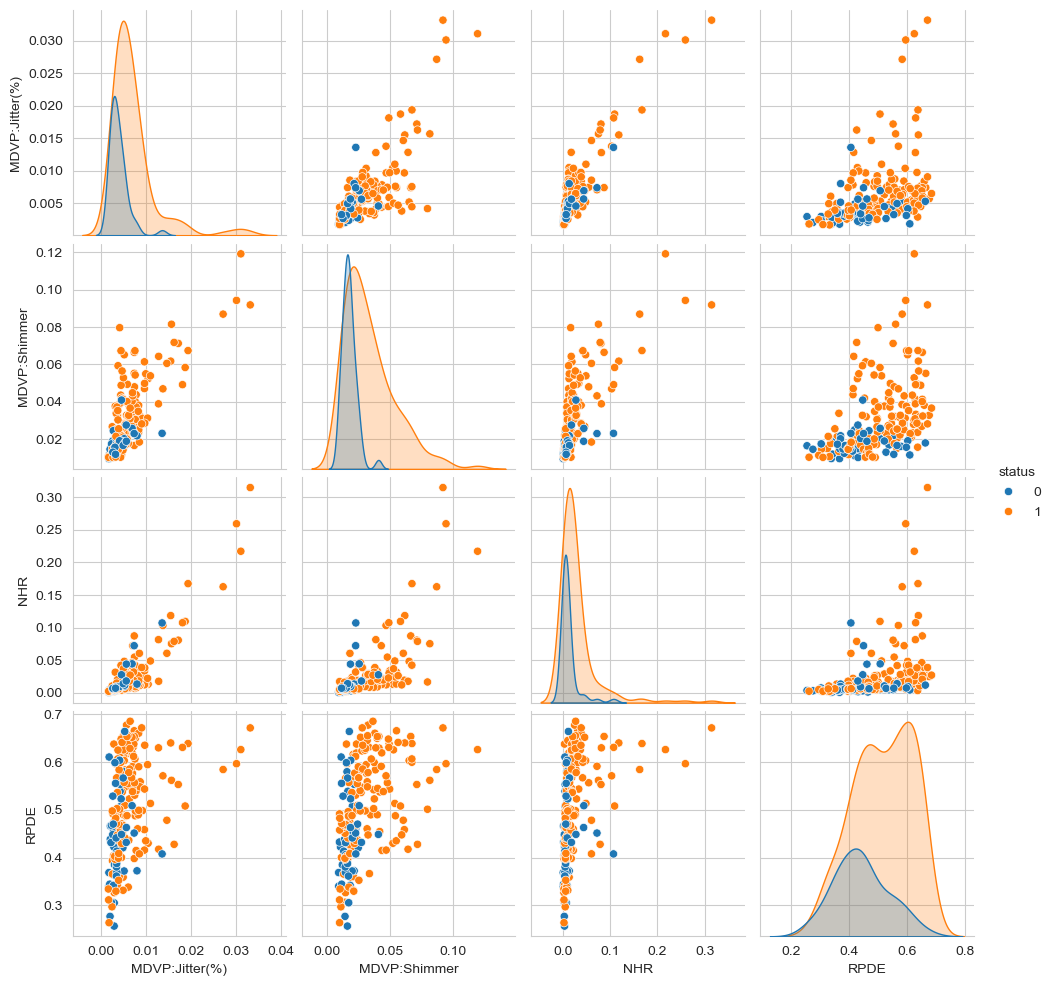

In [13]:

# Select a few features for pairwise comparison
selected = [
    "MDVP:Jitter(%)",
    "MDVP:Shimmer",
    "NHR",
    "RPDE",
    "status"
]

# Visualize relationships between selected features
sns.pairplot(df[selected], hue="status", diag_kind="kde")
plt.show()


In [15]:

# Define three machine learning models
model1 = LogisticRegression(max_iter=1000, random_state=42)

model2 = DecisionTreeClassifier(random_state=42)

model3 = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

# Store the models in a dictionary
models = {
    "Logistic Regression": model1,
    "Decision Tree": model2,
    "Random Forest": model3
}


In [16]:

# Train each model using the training data
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{name} training completed.")


Logistic Regression training completed.
Decision Tree training completed.
Random Forest training completed.


In [17]:

# Create a list to store model evaluation results
results = []

# Evaluate each trained model
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba)

    results.append([name, acc, prec, rec, f1, auc])

    print(f"\n{name} Results:")
    print(
        f"Accuracy: {acc:.4f}, "
        f"Precision: {prec:.4f}, "
        f"Recall: {rec:.4f}, "
        f"F1-score: {f1:.4f}, "
        f"AUC: {auc:.4f}"
    )
    print(classification_report(y_test, y_pred, zero_division=0))



Logistic Regression Results:
Accuracy: 0.9231, Precision: 0.9333, Recall: 0.9655, F1-score: 0.9492, AUC: 0.9241
              precision    recall  f1-score   support

           0       0.89      0.80      0.84        10
           1       0.93      0.97      0.95        29

    accuracy                           0.92        39
   macro avg       0.91      0.88      0.90        39
weighted avg       0.92      0.92      0.92        39


Decision Tree Results:
Accuracy: 0.8462, Precision: 0.8966, Recall: 0.8966, F1-score: 0.8966, AUC: 0.7983
              precision    recall  f1-score   support

           0       0.70      0.70      0.70        10
           1       0.90      0.90      0.90        29

    accuracy                           0.85        39
   macro avg       0.80      0.80      0.80        39
weighted avg       0.85      0.85      0.85        39


Random Forest Results:
Accuracy: 0.9231, Precision: 0.9333, Recall: 0.9655, F1-score: 0.9492, AUC: 0.9690
              preci

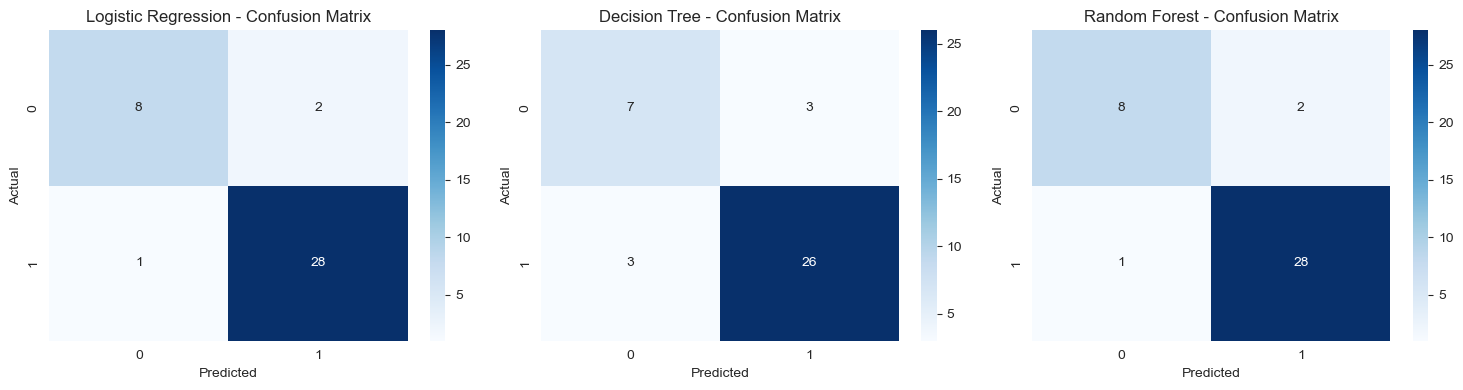

In [18]:

# Plot confusion matrices for all three models
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


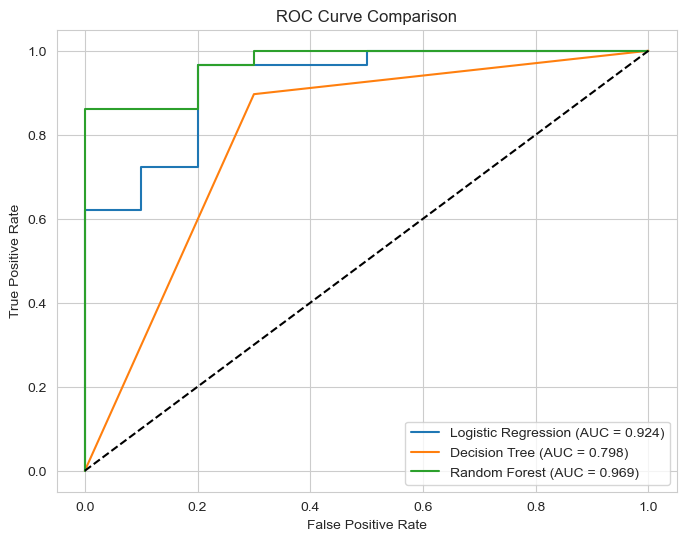

In [19]:

# Plot ROC curves to compare the models
plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    auc = roc_auc_score(y_test, y_proba)
    fpr, tpr, thresholds = roc_curve(y_test, y_proba)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

# Add the baseline for random predictions
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


In [20]:

# Create a comparison table for the three models
columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "AUC"
]

comp_df = pd.DataFrame(results, columns=columns)
comp_df = comp_df.round(4)

print("=== Model Comparison Table ===")
print(comp_df.to_string(index=False))

# Identify the model with the highest F1-score
best = comp_df.loc[comp_df["F1-score"].idxmax()]

print(
    f"\nBest Model: {best['Model']} "
    f"with F1-score = {best['F1-score']:.4f}"
)


=== Model Comparison Table ===
              Model  Accuracy  Precision  Recall  F1-score    AUC
Logistic Regression    0.9231     0.9333  0.9655    0.9492 0.9241
      Decision Tree    0.8462     0.8966  0.8966    0.8966 0.7983
      Random Forest    0.9231     0.9333  0.9655    0.9492 0.9690

Best Model: Logistic Regression with F1-score = 0.9492


In [21]:

print("""
==================== CONCLUSION ====================

Problem:
Predicting Parkinson's disease status using voice measurements.

Key Findings:
- Features such as Jitter, Shimmer, and NHR show
  differences between the two status groups.
- The dataset contains more Parkinson's-positive
  recordings than healthy recordings.

Best Model:
Selected based on the highest F1-score among the
three models tested.

Limitations:
- The dataset contains only 195 voice recordings,
  so the results may change with more data.
- Some recordings belong to the same participants,
  which may affect how well the model performs on
  completely new individuals.
- The model uses voice measurements only, so it does
  not consider other information about a person's health.

Future Improvements:
- Test the model on recordings from new participants.
- Explore additional features and more diverse data.
- Compare model performance using different evaluation
  methods.

=====================================================
""")



==================== CONCLUSION ====================

Problem:
Predicting Parkinson's disease status using voice measurements.

Key Findings:
- Features such as Jitter, Shimmer, and NHR show
  differences between the two status groups.
- The dataset contains more Parkinson's-positive
  recordings than healthy recordings.

Best Model:
Selected based on the highest F1-score among the
three models tested.

Limitations:
- The dataset contains only 195 voice recordings,
  so the results may change with more data.
- Some recordings belong to the same participants,
  which may affect how well the model performs on
  completely new individuals.
- The model uses voice measurements only, so it does
  not consider other information about a person's health.

Future Improvements:
- Test the model on recordings from new participants.
- Explore additional features and more diverse data.
- Compare model performance using different evaluation
  methods.


